## XAI - Final Project 
### Maryam Mounad

In [3]:
# Start by installing required packages
#!pip install uv
#!uv pip install pandas numpy rdkit scikit-learn matplotlib shap

In [2]:
# Load libraries
import pandas as pd
import numpy as np
from rdkit import Chem
from rdkit.Chem import AllChem
from rdkit.Chem import rdFingerprintGenerator
from rdkit.Chem import Draw, rdFingerprintGenerator
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
import IPython.display
from rdkit.Chem.Draw import rdMolDraw2D
from sklearn.metrics import (confusion_matrix,ConfusionMatrixDisplay,classification_report,
    roc_auc_score, accuracy_score)
import shap

from rdkit import RDLogger


d:\xai\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
assay = "PCBA-624202"
url = "https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/pcba.csv.gz"
data = pd.read_csv(url, usecols=["smiles", assay]) 
# pandas detects .gz and decompresses automatically

In [4]:
data = data.dropna().rename(columns={assay: "label"})
data["label"] = data["label"].astype(int)
print(data["label"].value_counts())

label
0    361799
1      3969
Name: count, dtype: int64


In [ ]:
'''#   smiles_to_ecfp4 function

def smiles_to_ecfp4(smiles):
    """
    Converts a list of SMILES strings into a 2D NumPy array of ECFP4 fingerprints.

    Parameters:
    smiles :  str
        SMILES string

    Returns:
    np.ndarray
    """

    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
      return None

    generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
    fp = generator.GetFingerprint(mol)
    arr = np.zeros((1,), dtype=int)
    AllChem.DataStructs.ConvertToNumpyArray(fp, arr)

    return arr'''

In [5]:
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator

# create once, outside the function: rebuilding it on every call is slow for 365k molecules
ECFP4_GEN = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

def smiles_to_ecfp4(smiles):
    """
    Convert a single SMILES string into an ECFP4 fingerprint.

    Parameters:
    smiles : str
        SMILES string

    Returns:
    np.ndarray of shape (2048,), dtype uint8, or None if parsing fails
    """
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    return ECFP4_GEN.GetFingerprintAsNumPy(mol)

In [6]:
# Convert SMILES to ECFP4 fingerprints
data['fingerprint'] = data['smiles'].apply(smiles_to_ecfp4)

[11:18:53] WARNING: not removing hydrogen atom without neighbors
[11:19:48] WARNING: not removing hydrogen atom without neighbors
[11:23:08] WARNING: not removing hydrogen atom without neighbors


In [7]:
# Filter out entries where SMILES parsing failed
df_clean = data.dropna(subset=["fingerprint"]).reset_index(drop=True)
#df_clean.head()
#df_clean.to_csv("pcba_clean.csv", index=False)

In [8]:
df_clean.shape

(365768, 3)

In [9]:
#get X (fingerprints) and y (Labels) from  clean_df
X = np.vstack(df_clean['fingerprint'].values)

y = df_clean['label'].values

print(X.shape)
print(y.shape)

(365768, 2048)
(365768,)


In [10]:
# Train/Test Split
X_train, X_test, y_train, y_test, smiles_train, smiles_test = train_test_split(
    X, y, df_clean["smiles"].values, test_size=0.2, stratify=y, random_state=42)

# Split SMILES and Fingerprints together using the SAME random_state

print(len(X_train))
print(len(X_test))

292614
73154


In [11]:
#BALANCING (downsampling)
#Find row indices for class 0 and class 1
idx_0 = np.where(y_train == 0)[0]
idx_1 = np.where(y_train == 1)[0]

# Determine target size (undersample majority class)
n_samples = min(len(idx_0), len(idx_1))

# Randomly sample indices for both classes without replacement
np.random.seed(42)
idx_0_sampled = np.random.choice(idx_0, size=n_samples, replace=False)
idx_1_sampled = np.random.choice(idx_1, size=n_samples, replace=False)

# Combine and shuffle the sampled indices
balanced_indices = np.hstack([idx_0_sampled, idx_1_sampled])
np.random.shuffle(balanced_indices)

# Slice X_train and y_train using the balanced indices
X_train_balanced = X_train[balanced_indices]
y_train_balanced = y_train[balanced_indices]

print("Before balancing:")
print(pd.Series(y_train).value_counts().to_dict())

print("\nAfter balancing:")
print(pd.Series(y_train_balanced).value_counts().to_dict())
print(f"\nShape of X_train_balanced: {X_train_balanced.shape}")  # Outputs clean (2 * n_samples, 2048)

Before balancing:
{0: 289439, 1: 3175}

After balancing:
{1: 3175, 0: 3175}

Shape of X_train_balanced: (6350, 2048)


In [12]:
print(f"\nShape of X_test: {X_test.shape}")


Shape of X_test: (73154, 2048)


## Model Training Random Forest

In [13]:
# Ensure X_train and X_test are 2D numpy arrays
X_train_balanced = np.vstack(X_train_balanced)
X_test = np.vstack(X_test)

print(X_train_balanced.ndim)
print(X_test.ndim)

2
2


In [14]:
# Train Random Forest Model
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train_balanced, y_train_balanced)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

### Model Evaluation

In [15]:
# predict the class (and probability) for the molecules in the test dataset (X_test)

from sklearn.metrics import balanced_accuracy_score

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate ROC-AUC score and accuracy 
roc_auc = roc_auc_score(y_test, y_prob)
accuracy = accuracy_score(y_test, y_pred)
balanced_accuracy = balanced_accuracy_score(y_test, y_pred)

print(f"ROC-AUC Score: {roc_auc:.4f}")
print(f"Accuracy Score : {accuracy:.4f}")
print(f"Balanced Accuracy Score: {balanced_accuracy:.4f}")

ROC-AUC Score: 0.8803
Accuracy Score : 0.7629
Balanced Accuracy Score: 0.7986


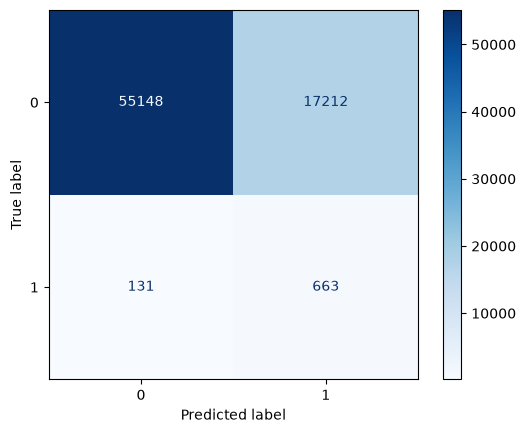

In [16]:
# plot confusion matrix 
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
disp.plot(cmap=plt.cm.Blues, values_format='d')
plt.show()

### Explainability

In [17]:
# Find indices for a True Positive (TP)
tp_indices = np.where((y_test == 1) & (y_pred == 1))[0]
TP_smiles = [smiles_test[tp_indx] for tp_indx in tp_indices]
print(len(TP_smiles))

# Find indices for a True Negatives (TN)
tn_indices =  np.where((y_test == 0) & (y_pred == 0))[0]
TN_smiles = [smiles_test[tn_indx] for tn_indx in tn_indices]

print(len(TN_smiles))

663
55148


In [18]:
#TASK choose 1 molecule (smiles string) to explain
smile_explain = TP_smiles[3]
print(smile_explain)

CN(C)/C=C1\N=C(c2ccc3c(c2)OCO3)OC1=O


In [19]:
# smiles_to_ecfp4 function to turn this smile string to ECFP4 format

mol_explain_unreshaped = smiles_to_ecfp4(smile_explain)
print(mol_explain_unreshaped)
print(mol_explain_unreshaped.shape)

# Reshape to (1, n_features) for SHAP prediction
mol_explain = mol_explain_unreshaped.reshape(1, -1)
print(mol_explain.shape)

[0 0 0 ... 0 0 0]
(2048,)
(1, 2048)


In [20]:
pred = model.predict(mol_explain)
prob = model.predict_proba(mol_explain) 
print(f"Predicted class: {pred[0]}, Probability of being active: {prob[0][1]:.4f}")

Predicted class: 1, Probability of being active: 0.8700


In [21]:
# set up the explainer using shap TreeExplainer
import shap.maskers

rng = np.random.default_rng(42)  # Use a fixed seed for reproducibility
idx = rng.choice(len(X_train_balanced), size=2000, replace=False)
background_data = X_train_balanced[idx].astype(np.float64)

masker= shap.maskers.Independent(background_data, max_samples=len(background_data))
explainer = shap.TreeExplainer(model, data=masker, feature_perturbation="interventional", model_output='probability')

d:\xai\.venv\Lib\site-packages\shap\explainers\_tree.py:277: UserWarning: Passing 2000 background samples may lead to slow runtimes. Consider using shap.sample(data, 100) to create a smaller background data set.
  warnings.warn(wmsg)


In [22]:
# get the shapley values for each bit in the molecule's fingerprint(mol_explain)
shap_values = explainer.shap_values(mol_explain)

print(shap_values)

[[[-1.61765873e-05  1.61765874e-05]
  [-6.32020701e-03  6.32020708e-03]
  [ 5.93509146e-04 -5.93509139e-04]
  ...
  [-4.51841634e-05  4.51841646e-05]
  [-1.24440744e-06  1.24440794e-06]
  [-4.51747828e-05  4.51747835e-05]]]


In [23]:
print(shap_values.shape)

(1, 2048, 2)


In [24]:
# To explain why the model predicts the molecule as active, slice Column 1
shap_class1_mol = shap_values[0, :, 1]
print(shap_class1_mol)

[ 1.61765874e-05  6.32020708e-03 -5.93509139e-04 ...  4.51841646e-05
  1.24440794e-06  4.51747835e-05]


In [25]:
#Map bit index to shapley value
values_shap = {bit_id: shap_val for bit_id, shap_val in enumerate(shap_class1_mol)}
print(values_shap)

{0: np.float64(1.617658740360639e-05), 1: np.float64(0.006320207078865138), 2: np.float64(-0.0005935091388581952), 3: np.float64(-4.011435765914939e-05), 4: np.float64(0.0002192977868126036), 5: np.float64(0.0007135920284972599), 6: np.float64(0.0), 7: np.float64(1.0202380872215145e-05), 8: np.float64(-0.0003908601726890595), 9: np.float64(4.186812329592726e-06), 10: np.float64(3.9523810119135304e-06), 11: np.float64(-1.2148245809839865e-07), 12: np.float64(5.042306308223488e-05), 13: np.float64(0.00023522899123963725), 14: np.float64(0.0003490461557719868), 15: np.float64(4.942460308484442e-06), 16: np.float64(2.83825760052423e-05), 17: np.float64(2.6791485652211122e-05), 18: np.float64(1.3716991378714737e-05), 19: np.float64(2.0371579266793562e-06), 20: np.float64(7.047619088552892e-06), 21: np.float64(-1.1182539844185158e-05), 22: np.float64(-2.279761894897092e-06), 23: np.float64(-3.2083334008348173e-06), 24: np.float64(7.022582984700421e-05), 25: np.float64(-0.0004084573451293636)

In [26]:
# Sort bits by absolute SHAP value
sorted_bits = sorted(values_shap.items(), key=lambda x: abs(x[1]), reverse=True)

In [27]:
# Print Top 10 Most Influential Features
for bit_id, shap_val in sorted_bits[:10]:
    direction = "Increases activity (+)" if shap_val > 0 else "Decreases activity (-)"
    print(f"Bit ID: {bit_id:4d} | SHAP Value: {shap_val:+.6f} | {direction}")

Bit ID:   80 | SHAP Value: +0.032799 | Increases activity (+)
Bit ID:  881 | SHAP Value: -0.031344 | Decreases activity (-)
Bit ID: 1160 | SHAP Value: +0.029169 | Increases activity (+)
Bit ID:  314 | SHAP Value: -0.027233 | Decreases activity (-)
Bit ID:  896 | SHAP Value: +0.022930 | Increases activity (+)
Bit ID:  935 | SHAP Value: +0.021654 | Increases activity (+)
Bit ID: 1810 | SHAP Value: +0.018376 | Increases activity (+)
Bit ID:   41 | SHAP Value: +0.016501 | Increases activity (+)
Bit ID:  656 | SHAP Value: +0.015730 | Increases activity (+)
Bit ID: 1019 | SHAP Value: +0.013461 | Increases activity (+)


In [28]:
#we can see the sum of SHAP values of all positively and negatively contributing bits
pos_sum = sum(val for bit, val in sorted_bits if val > 0)
neg_sum = sum(val for bit, val in sorted_bits if val < 0)
net_impact = pos_sum + neg_sum

print(f"Total Positive (active):  {pos_sum:+.6f}")
print(f"Total Negative (inactive): {neg_sum:+.6f}")
print(f"Net SHAP Shift for this molecule:      {net_impact:+.6f}")

Total Positive (active):  +0.493324
Total Negative (inactive): -0.130599
Net SHAP Shift for this molecule:      +0.362725


In [29]:
expected_value = explainer.expected_value[1]  #EV of class 1
print(expected_value)

0.5072750000000005


In [30]:
# Calculate total sum of SHAP contributions
total_shap_sum = np.sum(shap_class1_mol)

# Reconstructed probability from SHAP
reconstructed_prob = expected_value + total_shap_sum

# Actual model predicted probability
actual_prob = model.predict_proba(mol_explain)[0, 1]

print(f"Explainer Expected Value (Baseline) : {expected_value:.4f}")
print(f"Total Net SHAP Shift                 : {total_shap_sum:+.4f}")
print(f"Reconstructed Class 1 Probability   : {reconstructed_prob:.4f}")
print(f"Actual Model Class 1 Probability     : {actual_prob:.4f}")

Explainer Expected Value (Baseline) : 0.5073
Total Net SHAP Shift                 : +0.3627
Reconstructed Class 1 Probability   : 0.8700
Actual Model Class 1 Probability     : 0.8700


d:\xai\.venv\Lib\site-packages\shap\explainers\_tree.py:277: UserWarning: Passing 2000 background samples may lead to slow runtimes. Consider using shap.sample(data, 100) to create a smaller background data set.
  warnings.warn(wmsg)


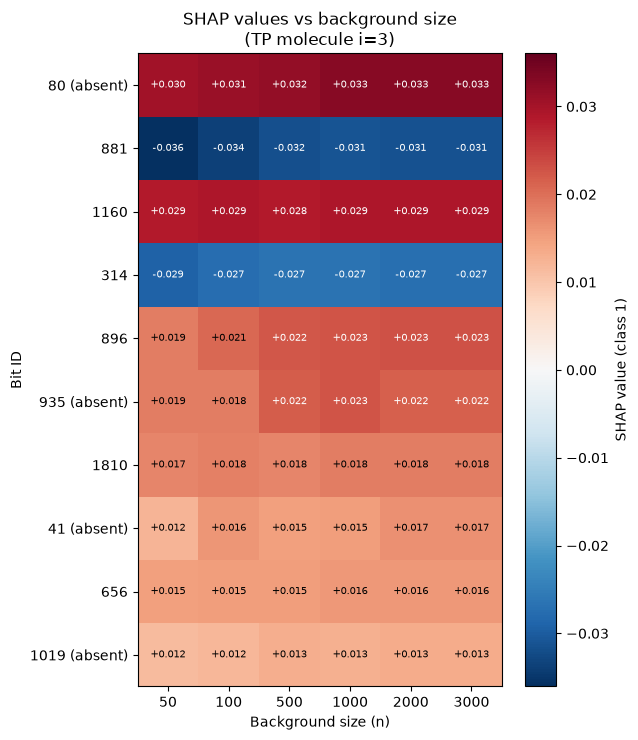

In [31]:
# Create a heatmap of SHAP values with respect to background size (n) for a given molecule (i) and for all TP molecules (i=None)

X_TP = X_test[tp_indices]
shap_bg_cache = {}  # (n, i) -> class 1 SHAP values, so re-plotting does not recompute


def shap_for_background(n, i=None):
    '''
    Class 1 SHAP values computed with the first n rows of background_data.

    The backgrounds are nested (n=100 is a subset of n=500, ...), so differences
    between sizes come from the added samples and not from a new random draw.

    Returns:
        np.ndarray of shape (2048,): SHAP values of molecule TP_smiles[i],
            or the mean SHAP values over all TP molecules if i is None.
    '''
    if (n, i) not in shap_bg_cache:
        bg = background_data[:n]
        masker_n = shap.maskers.Independent(bg, max_samples=n)
        explainer_n = shap.TreeExplainer(model, data=masker_n, feature_perturbation="interventional", model_output='probability')
        mols = X_TP if i is None else X_TP[i].reshape(1, -1)
        values = explainer_n.shap_values(mols, check_additivity=False)[:, :, 1]
        shap_bg_cache[(n, i)] = values.mean(axis=0)
    return shap_bg_cache[(n, i)]



def plot_shap_background_heatmap(i=None, sizes=( 50, 100, 500, 1000, 2000, 3000 ), n_top=10):
    # Rows: bits, columns: background sizes
    shap_matrix = np.column_stack([shap_for_background(n, i) for n in sizes])

    # Keep the n_top bits with the largest |SHAP| at the largest background size
    top_bits = np.argsort(-np.abs(shap_matrix[:, -1]))[:n_top]
    heat = shap_matrix[top_bits]

    # Symmetric color scale so that white = 0, red = active (+), blue = non-active (-)
    vmax = np.abs(heat).max()

    fig, ax = plt.subplots(figsize=(6.4, 7.5))
    im = ax.imshow(heat, cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")

    ax.set_xticks(range(len(sizes)))
    ax.set_xticklabels(sizes)
    ax.set_yticks(range(len(top_bits)))
    ax.set_yticklabels(top_bits)
    ax.set_xlabel("Background size (n)")
    ax.set_ylabel("Bit ID")

    # Write the value in each cell
    for row in range(heat.shape[0]):
        for col in range(heat.shape[1]):
            color = "white" if abs(heat[row, col]) > 0.6 * vmax else "black"
            ax.text(col, row, f"{heat[row, col]:+.3f}", ha="center", va="center", fontsize=7, color=color)

    if i is None:
        ax.set_title(f"Mean SHAP values vs background size\n(all {len(X_TP)} TP molecules)")
        label = "Mean SHAP value (class 1)"
    else:
        ax.set_title(f"SHAP values vs background size\n(TP molecule i={i})")
        label = "SHAP value (class 1)"
    fig.colorbar(im, ax=ax, label=label)

    fp_i = X_TP[i].astype(bool) if i is not None else None

    if i is None:
        # for the all-TP mean: show how often each bit is set across TP molecules
        frac = X_TP[:, top_bits].mean(axis=0)
        ylabels = [f"{b} ({f:.0%} set)" for b, f in zip(top_bits, frac)]
    else:
        ylabels = [f"{b}" if fp_i[b] else f"{b} (absent)" for b in top_bits]

    ax.set_yticklabels(ylabels)

    plt.tight_layout()
    plt.show()


plot_shap_background_heatmap(i=3)  # For the specific molecule TP_smiles[3]
#plot_shap_background_heatmap(i=None) # For the mean over all TP molecules, cant run it now bc it takes soo long to compute

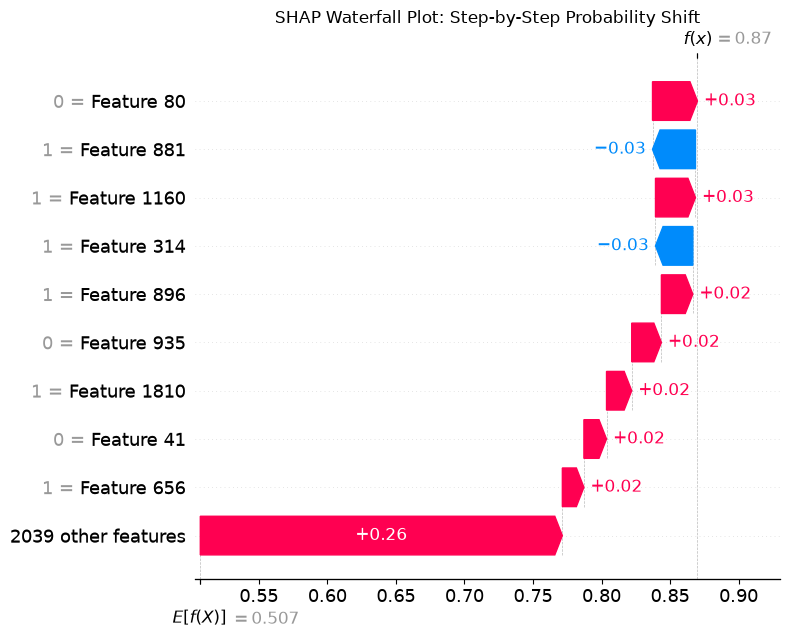

In [32]:
# Waterfall plot for a test molecule

smile_explain = TP_smiles[3]
mol_explain = smiles_to_ecfp4(smile_explain)
shap_values = explainer.shap_values(mol_explain.reshape(1, -1))[0, :, 1]

# Build Explanation object
sample_exp = shap.Explanation(
    values=shap_values,
    base_values=expected_value,
    data=mol_explain
)

# Plot Waterfall
plt.figure(figsize=(8, 6))
shap.plots.waterfall(sample_exp, max_display=10, show=False)
plt.title("SHAP Waterfall Plot: Step-by-Step Probability Shift")
plt.tight_layout()
plt.show()

In [33]:
# function that calculates the SHAP values  and returns sorted bits
def get_shap_bits(smiles, explainer):
  '''
  Computes and ranks Class 1 SHAP values for all fingerprint bits of a molecule.

    Converts a SMILES string into a 2,048-bit ECFP4 fingerprint and calculates
    the SHAP contribution of each bit toward the Class 1 (Permeable) prediction
    using a TreeExplainer. Bits are sorted by their absolute magnitude of impact.

    Returns:
        list of tuple[int, float]: A list of (bit_id, shap_value) tuples sorted
            in descending order by absolute SHAP value (|shap_value|).
  '''
  #turn molecule to ECFP4
  mol_explain = smiles_to_ecfp4(smiles)

  # Reshape to (1, n_features) for SHAP prediction
  mol_explain = mol_explain.reshape(1, -1)

  #get shap values
  shap_values = explainer.shap_values(mol_explain)
  shap_class1 = shap_values[0, :, 1]

  #get shap dictionary
  values_shap = {bit_id: shap_val for bit_id, shap_val in enumerate(shap_class1)}

  #sort bits
  sorted_bits = sorted(values_shap.items(), key=lambda x: abs(x[1]), reverse=True)

  return sorted_bits


- The visualize_mol_shap(smiles) function takes the SHAP values (using the function you defined above) and visualizes the molecule, highlighting the top 2 positive and top 2 negative important bits on the molecule


In [34]:

#@markdown The visualize_mol_shap(smiles) function takes the SHAP values (using the function you defined above) and visualizes the molecule, highlighting the top 5 positive and top 5 negative important bits on the molecule

def visualize_mol_shap(smiles, n_top=5):
    # 1. Convert to RDKit mol & generate bitInfo Map
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        print(f"Invalid SMILES string: {smiles}")
        return

    generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
    ao = rdFingerprintGenerator.AdditionalOutput()
    ao.AllocateBitInfoMap()
    generator.GetFingerprint(mol, additionalOutput=ao)
    bit_info = ao.GetBitInfoMap()

    # 2. Get sorted SHAP bits (tuple list: [(bit_id, shap_val), ...])
    sorted_bits = get_shap_bits(smiles, explainer)

    # 3. Filter strictly for PRESENT bits (bit_id in bit_info)
    present_positive = [b for b in sorted_bits if b[1] > 0 and b[0] in bit_info]
    present_negative = [b for b in sorted_bits if b[1] < 0 and b[0] in bit_info]

    # Select top N positive and top N negative bits
    selected_pos = present_positive[:n_top]
    selected_neg = present_negative[:n_top]

    bits_to_plot = selected_pos + selected_neg

    if not bits_to_plot:
        print("No active present bits found to highlight.")
        return

    # 4. Prepare dictionaries for single-plot overlay
    atom_colors = {}
    bond_colors = {}
    atoms_to_highlight = set()
    bonds_to_highlight = set()

    # Define RGB Color Palette: Red for Permeable (+), Blue for Non-Permeable (-)
    RED = (1.0, 0.2, 0.2)
    BLUE = (0.2, 0.4, 1.0)

    print(f"=== Overlaying Top {len(selected_pos)} (+) and Top {len(selected_neg)} (-) Present Features ===")

    for bit_id, shap_val in bits_to_plot:
        color = RED if shap_val > 0 else BLUE
        direction = "Active (+)" if shap_val > 0 else "Non-Active (-)"
        print(f"Bit ID: {bit_id:4d} | SHAP: {shap_val:+.6f} | {direction}")

        # Extract central atom and radius for each occurrence of the bit
        for central_atom_idx, radius in bit_info[bit_id]:
            atoms_to_highlight.add(central_atom_idx)
            atom_colors[central_atom_idx] = color

            if radius > 0:
                env_bonds = Chem.FindAtomEnvironmentOfRadiusN(mol, radius, central_atom_idx)
                for bond_idx in env_bonds:
                    bonds_to_highlight.add(bond_idx)
                    bond_colors[bond_idx] = color

                    bond = mol.GetBondWithIdx(bond_idx)
                    u = bond.GetBeginAtomIdx()
                    v = bond.GetEndAtomIdx()

                    atoms_to_highlight.update([u, v])
                    atom_colors[u] = color
                    atom_colors[v] = color

    # 5. Render single consolidated drawing
    drawer = rdMolDraw2D.MolDraw2DSVG(500, 350)

    options = drawer.drawOptions()
    options.useBWAtomPalette()  # Keeps non-highlighted atoms grayscale/clean
    options.continuousHighlight = True

    drawer.DrawMolecule(
        mol,
        highlightAtoms=list(atoms_to_highlight),
        highlightAtomColors=atom_colors,
        highlightBonds=list(bonds_to_highlight),
        highlightBondColors=bond_colors
    )
    drawer.FinishDrawing()

    IPython.display.display(IPython.display.SVG(drawer.GetDrawingText()))



In [35]:
sorted_bits_2 = get_shap_bits(smile_explain, explainer)
print(sorted_bits_2)

[(80, np.float64(0.03279918633826803)), (881, np.float64(-0.031343937201606505)), (1160, np.float64(0.02916906621656413)), (314, np.float64(-0.027232561050517134)), (896, np.float64(0.02293040757981504)), (935, np.float64(0.021653684111281785)), (1810, np.float64(0.018375640239242215)), (41, np.float64(0.016500978618979475)), (656, np.float64(0.01572998301440355)), (1019, np.float64(0.013461422690032976)), (350, np.float64(0.010504555204699756)), (694, np.float64(0.010234683518311258)), (378, np.float64(0.010207448249587942)), (1152, np.float64(0.009199414602086033)), (1476, np.float64(0.008972056637676957)), (807, np.float64(0.0074582943352369145)), (738, np.float64(0.007176109313651395)), (309, np.float64(0.006738348160409217)), (1163, np.float64(-0.006652013881864434)), (1, np.float64(0.006320207078865138)), (926, np.float64(-0.005594313990419884)), (1970, np.float64(0.005560496207508415)), (1035, np.float64(0.005195296541894024)), (1058, np.float64(-0.005180965795688507)), (1480, n

=== Overlaying Top 3 (+) and Top 3 (-) Present Features ===
Bit ID: 1160 | SHAP: +0.029169 | Active (+)
Bit ID:  896 | SHAP: +0.022930 | Active (+)
Bit ID: 1810 | SHAP: +0.018376 | Active (+)
Bit ID:  881 | SHAP: -0.031344 | Non-Active (-)
Bit ID:  314 | SHAP: -0.027233 | Non-Active (-)
Bit ID: 1163 | SHAP: -0.006652 | Non-Active (-)


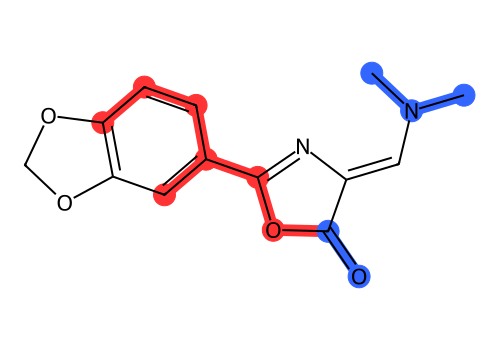

In [115]:
#We can use this function to visualize the top 2 most positively contributing structures and top 2 most negatively contributing structrures to the model's prediction
visualize_mol_shap(smile_explain, n_top=3)  # Visualize top 5 positive and top 5 negative contributing bits

### Global Feature Importance

-  try the interventional with 1000, and 1000
then the tree_path_dependent, then model.feature_importances

In [37]:
rng = np.random.default_rng(42)  # Use a fixed seed for reproducibility
idx = rng.choice(len(X_train_balanced), size=1000, replace=False)
bg = X_train_balanced[idx].astype(np.float64)
    
masker= shap.maskers.Independent(bg, max_samples=len(bg))
explainer_global_inter = shap.TreeExplainer(model, data=masker, feature_perturbation="interventional", model_output='probability')

In [39]:
act_idx = np.where(y_test == 1)[0]
print("actives in test:", len(act_idx))
inact_idx = np.where(y_test == 0)[0]
print("inactives in test:", len(inact_idx))

rng = np.random.default_rng(42)
n_act = min(len(act_idx), 200)
strat_idx = np.concatenate([
    rng.choice(act_idx, n_act, replace=False),
    rng.choice(inact_idx, n_act, replace=False),
])
X_sample = X_test[strat_idx].astype(np.float64)
print("Sample size:", len(X_sample))

actives in test: 794
inactives in test: 72360
Sample size: 400


In [40]:
shap_values_global = explainer_global_inter.shap_values(X_sample)

100%|===================| 799/800 [12:17<00:00]        

In [41]:
shap_class1 = shap_values_global[:, :, 1]

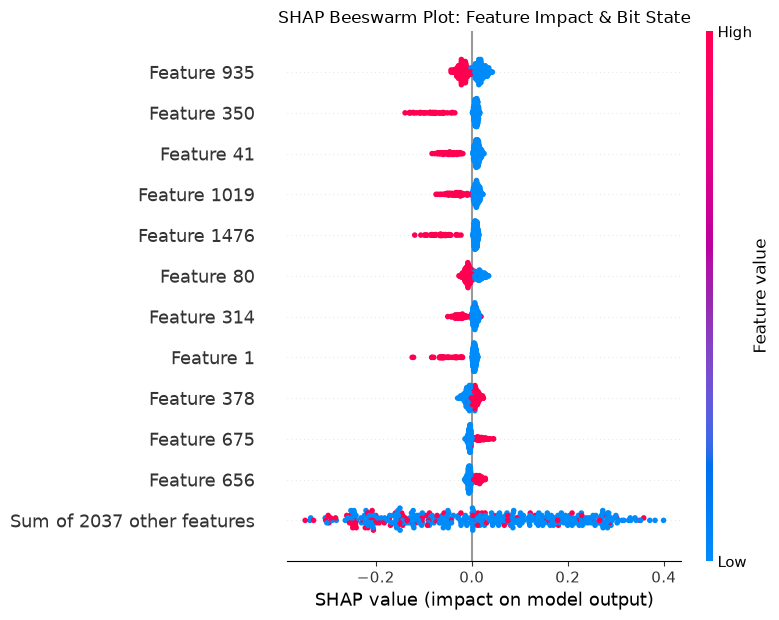

In [42]:
# Create Explanation object for Beeswarm plot
explanation = shap.Explanation(values=shap_class1,
    base_values=explainer_global_inter.expected_value[1],
    data=X_sample)

plt.figure(figsize=(10, 6))
shap.plots.beeswarm(explanation, max_display=12, show=False)
plt.title("SHAP Beeswarm Plot: Feature Impact & Bit State")
plt.tight_layout()
plt.show()

In [ ]:
# @markdown the following **highlight_bit_on_molecule(bit, smiles)** function can be used to visualize the structure the bit represents. The substructure gets mapped on the molecule (if present) or its representation visualized (if absent)*
from rdkit.Chem.Draw import rdMolDraw2D
import IPython.display

def highlight_bit_on_molecule(bit_id, mol, width=500, height=350):
    """
    Highlights the atomic environment corresponding to `bit_id` on a specific molecule.
    Accepts either an RDKit Mol object or a SMILES string.
    """
    # 1. Handle string SMILES input if passed instead of RDKit Mol object
    if isinstance(mol, str):
        smi = mol
        mol = Chem.MolFromSmiles(smi)
        if mol is None:
            print(f"Invalid SMILES string provided: {smi}")
            return

    # 2. Generate Morgan Fingerprint with BitInfo Map for this molecule
    generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
    ao = rdFingerprintGenerator.AdditionalOutput()
    ao.AllocateBitInfoMap()
    generator.GetFingerprint(mol, additionalOutput=ao)
    bit_info = ao.GetBitInfoMap()

    # 3. Check if the bit exists in this specific molecule
    if bit_id not in bit_info:
        print(f"Bit {bit_id} not present in molecule")
        print()
        highlight_bit(bit_id, X, df_clean['smiles'].values)

        return

    # 4. Set Highlight Color to Green (RGB: 0.1, 0.7, 0.3)
    color = (0.1, 0.7, 0.3)

    # 5. Extract Central Atoms and Radius Environments
    atoms_to_highlight = set()
    bonds_to_highlight = set()
    atom_colors = {}
    bond_colors = {}

    for central_atom_idx, radius in bit_info[bit_id]:
        atoms_to_highlight.add(central_atom_idx)
        atom_colors[central_atom_idx] = color

        if radius > 0:
            env_bonds = Chem.FindAtomEnvironmentOfRadiusN(mol, radius, central_atom_idx)
            for bond_idx in env_bonds:
                bonds_to_highlight.add(bond_idx)
                bond_colors[bond_idx] = color

                # Add attached atoms at the ends of environment bonds
                bond = mol.GetBondWithIdx(bond_idx)
                u = bond.GetBeginAtomIdx()
                v = bond.GetEndAtomIdx()

                atoms_to_highlight.update([u, v])
                atom_colors[u] = color
                atom_colors[v] = color

    # 6. Render SVG Drawing
    drawer = rdMolDraw2D.MolDraw2DSVG(width, height)
    options = drawer.drawOptions()
    options.useBWAtomPalette()  # Keeps non-highlighted atoms in clean grayscale
    options.continuousHighlight = True

    drawer.DrawMolecule(
        mol,
        highlightAtoms=list(atoms_to_highlight),
        highlightAtomColors=atom_colors,
        highlightBonds=list(bonds_to_highlight),
        highlightBondColors=bond_colors
    )
    drawer.FinishDrawing()

    # Display SVG in Notebook
    print(f"Bit {bit_id} is present in molecule:")
    print(f"Displaying Bit ID {bit_id}")
    IPython.display.display(IPython.display.SVG(drawer.GetDrawingText()))

def highlight_bit(bit_id, X_matrix, smiles_list, smiles=None, shap_matrix=None, width=500, height=350):
    """
    Finds a representative molecule containing `bit_id`, highlights its
    atomic environment in green, and displays the rendered SVG.
    """
    # 1. Find indices of molecules containing the target bit
    present_indices = np.where(X_matrix[:, bit_id] == 1)[0]

    if len(present_indices) == 0:
        print(f"Bit {bit_id} is not present in any provided molecule.")
        return

    if smiles is None :
      # Pick the first representative molecule
      sample_idx = present_indices[0]
      smi = smiles_list[sample_idx]
    else:
      smi = smiles

    mol = Chem.MolFromSmiles(smi)

    if mol is None:
        print(f"Invalid SMILES encountered at index {sample_idx}: {smi}")
        return

    # 2. Generate Morgan Fingerprint with BitInfo Map
    generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
    ao = rdFingerprintGenerator.AdditionalOutput()
    ao.AllocateBitInfoMap()
    generator.GetFingerprint(mol, additionalOutput=ao)
    bit_info = ao.GetBitInfoMap()

    img = Draw.DrawMorganBit(mol, bit_id, bit_info)
    display(img)

In [44]:
shap_class1.shape

(400, 2048)

Top 15 bits: [ 935  350   41 1019 1476   80  314    1  378  675  656 1480  881 1750
 1160]
--- Bit ID 935 | mean |SHAP| = 0.0188 ---
Set in 47.0% of the sampled molecules
Mean SHAP when present: -0.0193
Mean SHAP when absent:  +0.0182
Role when present: Activity penalty (-)
Example molecule: test index 0
Central atom index: 4 | Radius: 0
(bit set by 2 environments in this molecule)


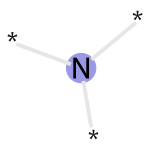

Bit 935 is present in molecule:
Displaying Bit ID 935


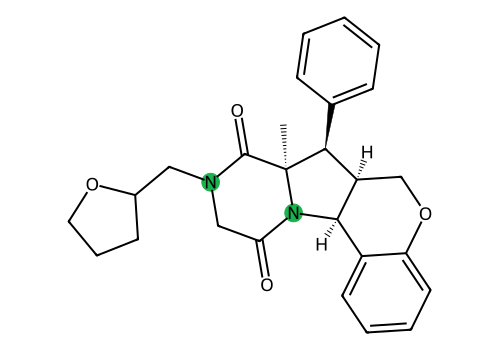

--------------------------------------------------------------------------------
--- Bit ID 350 | mean |SHAP| = 0.0178 ---
Set in 11.2% of the sampled molecules
Mean SHAP when present: -0.0861
Mean SHAP when absent:  +0.0091
Role when present: Activity penalty (-)
Example molecule: test index 15
Central atom index: 9 | Radius: 0


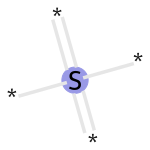

Bit 350 is present in molecule:
Displaying Bit ID 350


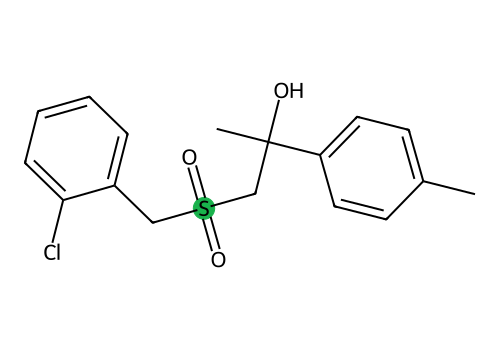

--------------------------------------------------------------------------------
--- Bit ID 41 | mean |SHAP| = 0.0170 ---
Set in 16.0% of the sampled molecules
Mean SHAP when present: -0.0463
Mean SHAP when absent:  +0.0114
Role when present: Activity penalty (-)
Example molecule: test index 8
Central atom index: 5 | Radius: 1


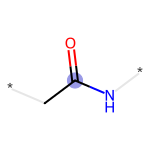

Bit 41 is present in molecule:
Displaying Bit ID 41


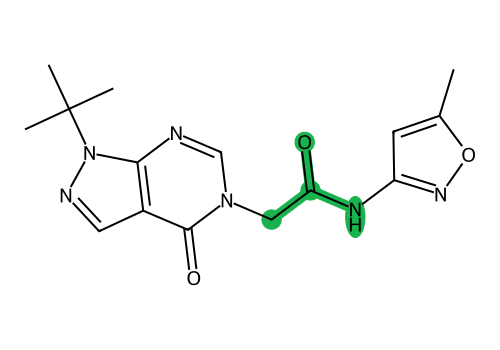

--------------------------------------------------------------------------------
--- Bit ID 1019 | mean |SHAP| = 0.0154 ---
Set in 19.5% of the sampled molecules
Mean SHAP when present: -0.0357
Mean SHAP when absent:  +0.0105
Role when present: Activity penalty (-)
Example molecule: test index 0
Central atom index: 6 | Radius: 0
(bit set by 4 environments in this molecule)


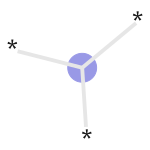

Bit 1019 is present in molecule:
Displaying Bit ID 1019


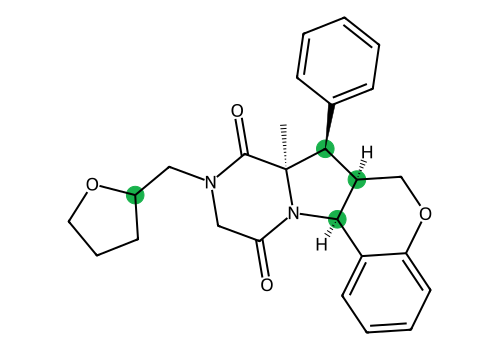

--------------------------------------------------------------------------------
--- Bit ID 1476 | mean |SHAP| = 0.0153 ---
Set in 12.0% of the sampled molecules
Mean SHAP when present: -0.0661
Mean SHAP when absent:  +0.0083
Role when present: Activity penalty (-)
Example molecule: test index 15
Central atom index: 10 | Radius: 1
(bit set by 2 environments in this molecule)


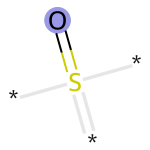

Bit 1476 is present in molecule:
Displaying Bit ID 1476


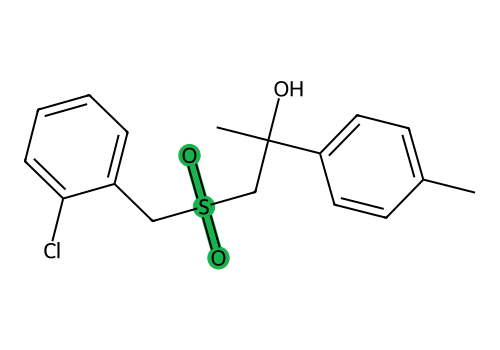

--------------------------------------------------------------------------------
--- Bit ID 80 | mean |SHAP| = 0.0112 ---
Set in 64.0% of the sampled molecules
Mean SHAP when present: -0.0082
Mean SHAP when absent:  +0.0154
Role when present: Activity penalty (-)
Example molecule: test index 0
Central atom index: 5 | Radius: 0


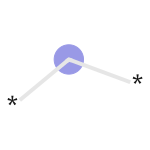

Bit 80 is present in molecule:
Displaying Bit ID 80


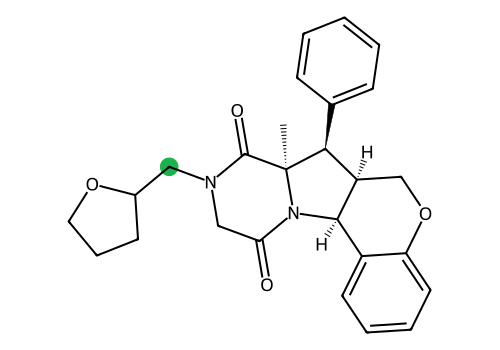

--------------------------------------------------------------------------------
--- Bit ID 314 | mean |SHAP| = 0.0106 ---
Set in 21.0% of the sampled molecules
Mean SHAP when present: -0.0230
Mean SHAP when absent:  +0.0071
Role when present: Activity penalty (-)
Example molecule: test index 0
Central atom index: 3 | Radius: 1
(bit set by 2 environments in this molecule)


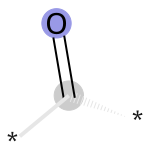

Bit 314 is present in molecule:
Displaying Bit ID 314


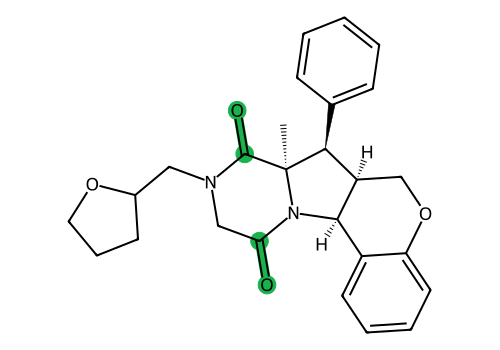

--------------------------------------------------------------------------------
--- Bit ID 1 | mean |SHAP| = 0.0103 ---
Set in 9.8% of the sampled molecules
Mean SHAP when present: -0.0526
Mean SHAP when absent:  +0.0058
Role when present: Activity penalty (-)
Example molecule: test index 3
Central atom index: 6 | Radius: 0


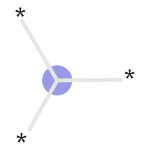

Bit 1 is present in molecule:
Displaying Bit ID 1


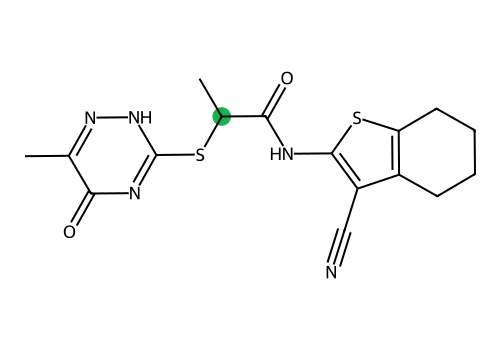

--------------------------------------------------------------------------------
--- Bit ID 378 | mean |SHAP| = 0.0084 ---
Set in 49.2% of the sampled molecules
Mean SHAP when present: +0.0080
Mean SHAP when absent:  -0.0083
Role when present: Activity enhancer (+)
Example molecule: test index 2
Central atom index: 16 | Radius: 0
(bit set by 3 environments in this molecule)


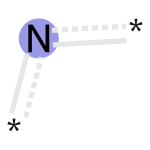

Bit 378 is present in molecule:
Displaying Bit ID 378


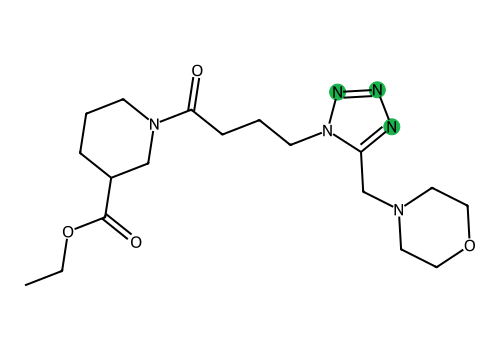

--------------------------------------------------------------------------------
--- Bit ID 675 | mean |SHAP| = 0.0075 ---
Set in 20.8% of the sampled molecules
Mean SHAP when present: +0.0187
Mean SHAP when absent:  -0.0046
Role when present: Activity enhancer (+)
Example molecule: test index 3
Central atom index: 12 | Radius: 0


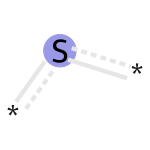

Bit 675 is present in molecule:
Displaying Bit ID 675


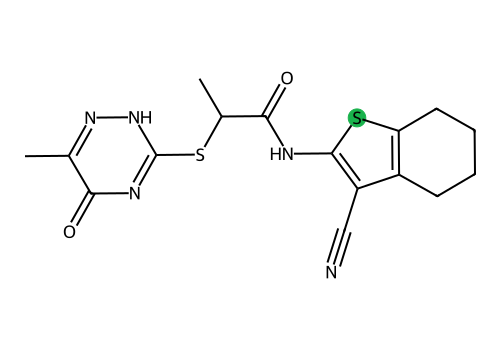

--------------------------------------------------------------------------------
--- Bit ID 656 | mean |SHAP| = 0.0074 ---
Set in 28.2% of the sampled molecules
Mean SHAP when present: +0.0121
Mean SHAP when absent:  -0.0055
Role when present: Activity enhancer (+)
Example molecule: test index 0
Central atom index: 10 | Radius: 0
(bit set by 2 environments in this molecule)


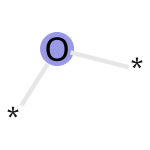

Bit 656 is present in molecule:
Displaying Bit ID 656


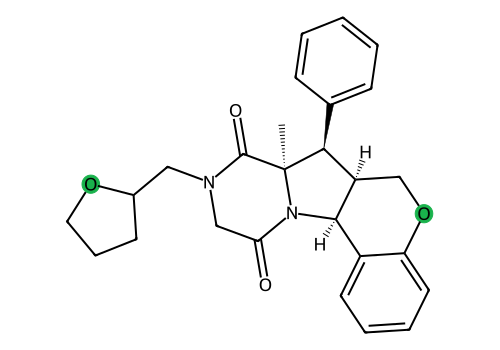

--------------------------------------------------------------------------------
--- Bit ID 1480 | mean |SHAP| = 0.0066 ---
Set in 23.0% of the sampled molecules
Mean SHAP when present: -0.0140
Mean SHAP when absent:  +0.0043
Role when present: Activity penalty (-)
Example molecule: test index 2
Central atom index: 8 | Radius: 1
(bit set by 3 environments in this molecule)


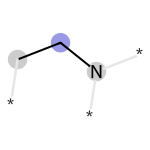

Bit 1480 is present in molecule:
Displaying Bit ID 1480


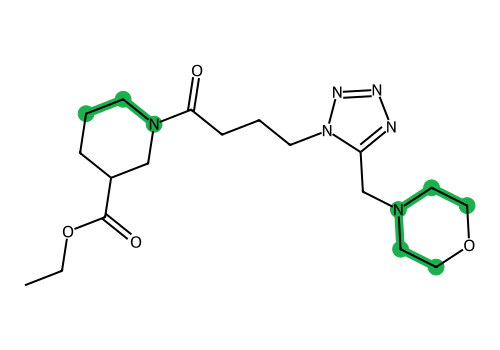

--------------------------------------------------------------------------------
--- Bit ID 881 | mean |SHAP| = 0.0065 ---
Set in 11.2% of the sampled molecules
Mean SHAP when present: -0.0312
Mean SHAP when absent:  +0.0034
Role when present: Activity penalty (-)
Example molecule: test index 12
Central atom index: 2 | Radius: 0
(bit set by 2 environments in this molecule)


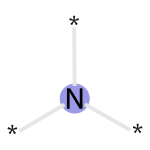

Bit 881 is present in molecule:
Displaying Bit ID 881


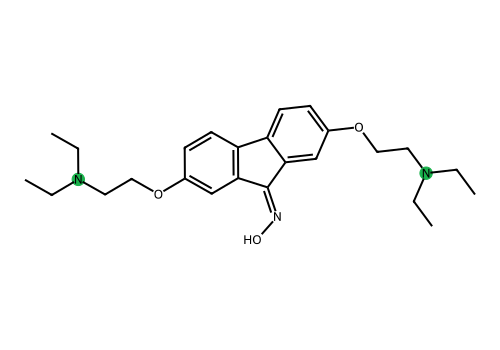

--------------------------------------------------------------------------------
--- Bit ID 1750 | mean |SHAP| = 0.0065 ---
Set in 93.8% of the sampled molecules
Mean SHAP when present: +0.0037
Mean SHAP when absent:  -0.0486
Role when present: Activity enhancer (+)
Example molecule: test index 0
Central atom index: 17 | Radius: 1
(bit set by 4 environments in this molecule)


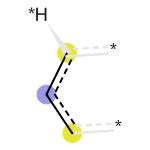

Bit 1750 is present in molecule:
Displaying Bit ID 1750


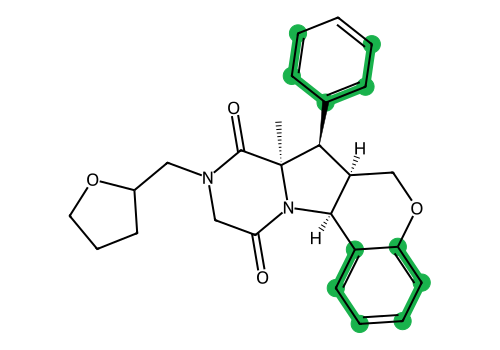

--------------------------------------------------------------------------------
--- Bit ID 1160 | mean |SHAP| = 0.0065 ---
Set in 15.2% of the sampled molecules
Mean SHAP when present: +0.0248
Mean SHAP when absent:  -0.0031
Role when present: Activity enhancer (+)
Example molecule: test index 5
Central atom index: 4 | Radius: 1


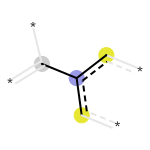

Bit 1160 is present in molecule:
Displaying Bit ID 1160


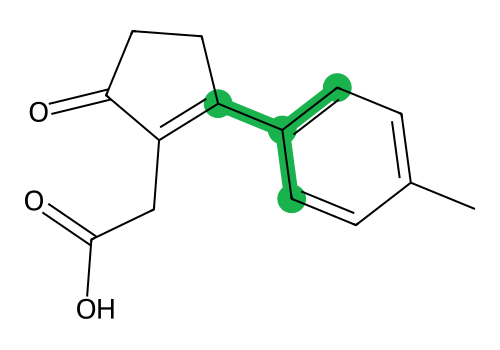

--------------------------------------------------------------------------------


In [ ]:
# The exact 500 test rows used to compute shap_class1.

X_shap = X_test[strat_idx]

mean_abs_shap = np.mean(np.abs(shap_class1), axis=0)
top_bits = np.argsort(mean_abs_shap)[::-1][:15]
print("Top 15 bits:", top_bits)

for bit_id in top_bits:
    print(f"--- Bit ID {bit_id} | mean |SHAP| = {mean_abs_shap[bit_id]:.4f} ---")

    # 1. SHAP statistics on the 500 sampled molecules
    present = X_shap[:, bit_id] == 1
    frac_present = present.mean()
    mean_shap_present = shap_class1[present, bit_id].mean() if present.any() else np.nan
    mean_shap_absent = shap_class1[~present, bit_id].mean() if (~present).any() else np.nan

    print(f"Set in {frac_present:.1%} of the sampled molecules")
    print(f"Mean SHAP when present: {mean_shap_present:+.4f}")
    print(f"Mean SHAP when absent:  {mean_shap_absent:+.4f}")

    if np.isnan(mean_shap_present):
        print("Bit never set in the sample: it matters only through its absence.")
    else:
        role = "Activity enhancer (+)" if mean_shap_present > 0 else "Activity penalty (-)"
        print(f"Role when present: {role}")

    # 2. Find an example molecule in the full test set that has this bit
    present_indices = np.where(X_test[:, bit_id] == 1)[0]
    if len(present_indices) == 0:
        print(f"Bit ID {bit_id} is not set in any test set molecule.")
        print("-" * 80)
        continue

    sample_idx = present_indices[0]
    smi = smiles_test[sample_idx]
    mol = Chem.MolFromSmiles(smi)

    # 3. Bit info, using the same generator settings as the model's fingerprints
    ao = rdFingerprintGenerator.AdditionalOutput()
    ao.AllocateBitInfoMap()
    ECFP4_GEN.GetFingerprint(mol, additionalOutput=ao)
    bit_info = {k: list(v) for k, v in ao.GetBitInfoMap().items()}

    # 4. Draw the bit environment
    if bit_id in bit_info:
        atom_idx, radius = bit_info[bit_id][0]
        print(f"Example molecule: test index {sample_idx}")
        print(f"Central atom index: {atom_idx} | Radius: {radius}")
        if len(bit_info[bit_id]) > 1:
            print(f"(bit set by {len(bit_info[bit_id])} environments in this molecule)")
        display(Draw.DrawMorganBit(mol, bit_id, bit_info))
        highlight_bit_on_molecule(bit_id, smi)
    else:
        print(f"Could not extract bit environment for Bit ID {bit_id}.")

    print("-" * 80)

In [ ]:
y_shap = y_test[strat_idx]          # labels of the 500 sampled molecules
print("actives / inactives:", np.bincount(y_shap)[::-1])

# Ranking by direction (signed mean SHAP when present)
mean_when_present = np.array([
    shap_class1[X_shap[:, b] == 1, b].mean() if (X_shap[:, b] == 1).any() else 0.0
    for b in range(X_shap.shape[1])
])
freq = X_shap.mean(axis=0)

top_enh = np.argsort(-mean_when_present)[:10]
top_pen = np.argsort(mean_when_present)[:10]

print("Top enhancers:")
for b in top_enh:
    print(f"Bit {b:4d} | mean SHAP when present {mean_when_present[b]:+.4f} | set in {freq[b]:.1%}")
print("Top penalties:")
for b in top_pen:
    print(f"Bit {b:4d} | mean SHAP when present {mean_when_present[b]:+.4f} | set in {freq[b]:.1%}")

# Global importance on actives only
act = y_shap == 1
if act.any():
    imp_act = np.abs(shap_class1[act]).mean(axis=0)
    print("Top bits for actives:", np.argsort(-imp_act)[:10])

Bit 896 is present in molecule:
Displaying Bit ID 896


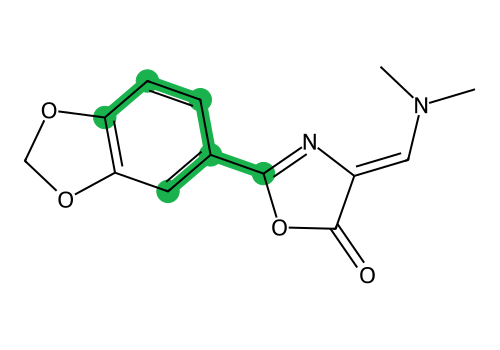

In [52]:
highlight_bit_on_molecule(896, smile_explain)

Bit 1160 not present in molecule



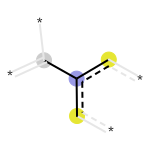

In [77]:
highlight_bit_on_molecule(1160, smile_explain_2)

In [74]:
smile_explain_2 = TP_smiles[6]

Bit 1750 is present in molecule:
Displaying Bit ID 1750


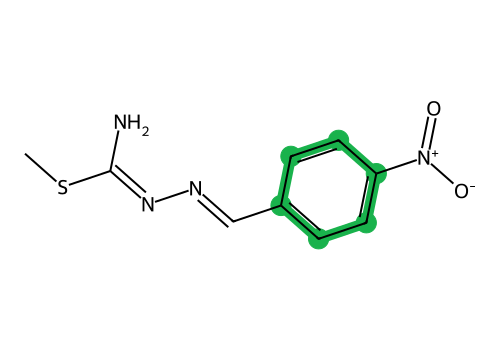

In [75]:
highlight_bit_on_molecule(1750, smile_explain_2)

In [78]:
explainer_tree_dependent = shap.TreeExplainer(model, feature_perturbation="tree_path_dependent")

In [86]:
shap_values_global_td = explainer_tree_dependent.shap_values(X_sample, check_additivity=False)

In [ ]:
shap_class1_td = shap_values_global_td[:, :, 1]

# Create Explanation object for Beeswarm plot
explanation = shap.Explanation(values=shap_class1_td,
    base_values=explainer_tree_dependent.expected_value[1],
    data=X_sample)

plt.figure(figsize=(10, 6))
shap.plots.beeswarm(explanation, max_display=12, show=False)
plt.title("SHAP Beeswarm Plot: Feature Impact & Bit State")
plt.tight_layout()
plt.show()

In [202]:
#drug = 'OCC1=CNC2=CC=CC=C12' #Indole-3-Carbinol 0.65

drug = 'OC1=CC=C(C=C1)C1=COC2=CC(O)=CC(O)=C2C1=O' #genistein 0.77

#drug = 'OC1=CC=C(\C=C\C2=CC(O)=CC(O)=C2)C=C1' #Resveratrol 0.84

#drug = 'COC1=CC(\C=C\C(=O)CC(=O)\C=C\C2=CC(OC)=C(O)C=C2)=CC=C1O' #Curcumin #0.57

In [203]:
mol_drug = smiles_to_ecfp4(drug)
mol_drug.shape

(2048,)

In [204]:
pred = model.predict(mol_drug.reshape(1, -1))
prob = model.predict_proba(mol_drug.reshape(1, -1)) 
print(f"Predicted class: {pred[0]}, Probability of being active: {prob[0][1]:.4f}")

Predicted class: 1, Probability of being active: 0.7700


=== Overlaying Top 2 (+) and Top 2 (-) Present Features ===
Bit ID: 1160 | SHAP: +0.030289 | Active (+)
Bit ID:  896 | SHAP: +0.025824 | Active (+)
Bit ID: 1984 | SHAP: -0.028351 | Non-Active (-)
Bit ID:  314 | SHAP: -0.020328 | Non-Active (-)


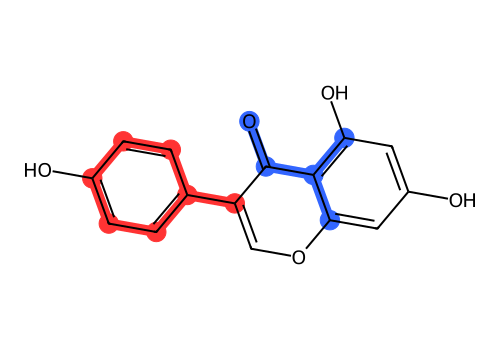

In [205]:
visualize_mol_shap(drug, n_top=2)

Bit 1750 is present in molecule:
Displaying Bit ID 1750


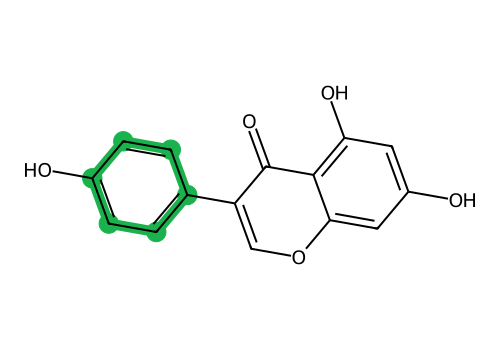

In [175]:
highlight_bit_on_molecule(1750, drug)

In [ ]:
highlight_bit_on_molecule(656, drug)

Bit 1160 is present in molecule:
Displaying Bit ID 1160


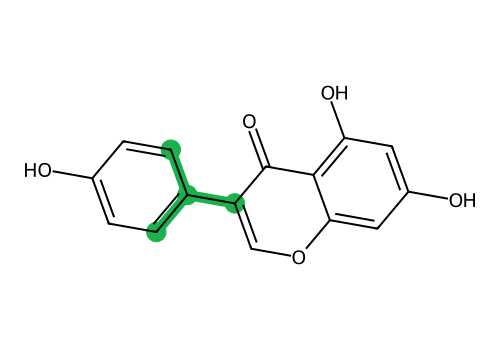

In [180]:
highlight_bit_on_molecule(1160, drug)

### Random Forest feature importance

In [102]:
rf_importance = pd.Series(
    model.feature_importances_,
    index=np.arange(model.n_features_in_),   # bit IDs 0–2047
    name="gini_importance",
).sort_values(ascending=False)

print(rf_importance.head(20))

350     0.012649
1476    0.011687
935     0.010010
1019    0.008416
41      0.007901
314     0.006101
80      0.006079
1       0.006027
319     0.005711
800     0.005080
1480    0.004714
926     0.004265
1765    0.003945
881     0.003881
378     0.003689
1750    0.003442
656     0.003418
675     0.003405
650     0.003392
843     0.003339
Name: gini_importance, dtype: float64


In [103]:
X_s = X_test[strat_idx].astype(np.float64)
y_s = y_test[strat_idx]
sv_s = shap_class1    # must have been computed on X_test[strat_idx], in the same order

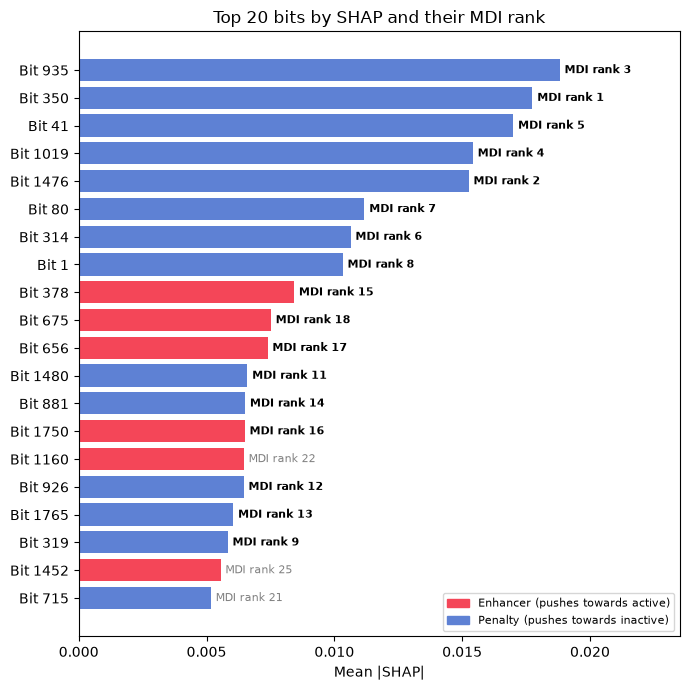

In [114]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import rankdata

k = 20
shap_imp = np.abs(sv_s).mean(axis=0)
mdi_imp = model.feature_importances_

# MDI rank for every bit (1 = most important)
mdi_rank = rankdata(-mdi_imp, method="min").astype(int)

# Direction when present
present = X_s == 1
n_present = present.sum(axis=0)
mean_when_present = np.where(n_present > 0,
                             (sv_s * present).sum(axis=0) / np.maximum(n_present, 1), 0.0)

top = np.argsort(-shap_imp)[:k]
colors = ["lightgrey" if n_present[b] == 0 else
          "#F44658" if mean_when_present[b] > 0 else "#5e81d4" for b in top]

fig, ax = plt.subplots(figsize=(7, 7))
y = np.arange(k)
ax.barh(y, shap_imp[top], color=colors)
ax.set_yticks(y)
ax.set_yticklabels([f"Bit {b}" for b in top])
ax.invert_yaxis()
ax.set_xlabel("Mean |SHAP|")

# MDI rank next to each bar; bold if also in MDI top 20
xmax = shap_imp[top].max()
for yi, b in zip(y, top):
    r = mdi_rank[b]
    ax.text(shap_imp[b] + 0.01 * xmax, yi, f"MDI rank {r}", va="center", fontsize=8,
            fontweight="bold" if r <= k else "normal",
            color="black" if r <= k else "grey")
ax.set_xlim(0, xmax * 1.25)   # room for the labels

n_shared = int((mdi_rank[top] <= k).sum())
ax.set_title(f"Top {k} bits by SHAP and their MDI rank")

ax.legend(handles=[
    Patch(color="#F44658", label="Enhancer (pushes towards active)"),
    Patch(color="#5e81d4", label="Penalty (pushes towards inactive)"),
], loc="lower right", fontsize=8)

plt.tight_layout()
plt.show()